In [3]:
from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["Species"] = [iris.target_names[i] for i in iris.target]

print("IRIS FLOWER CLASSIFICATION PROJECT")
print("Total Samples:", len(df))
print("Features:", list(iris.feature_names))
print("Flower Species:", list(iris.target_names))

display(df.head())

IRIS FLOWER CLASSIFICATION PROJECT
Total Samples: 150
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Flower Species: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


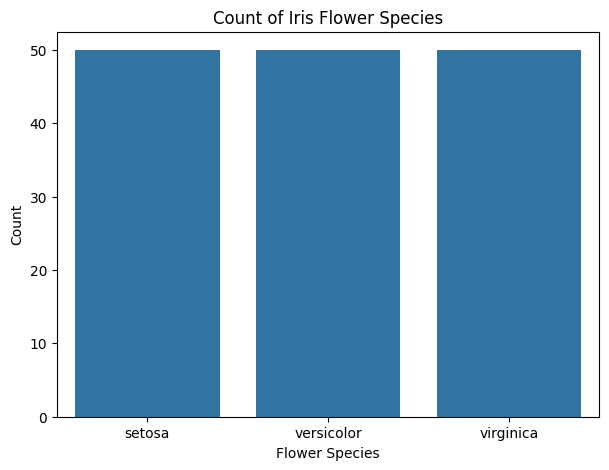

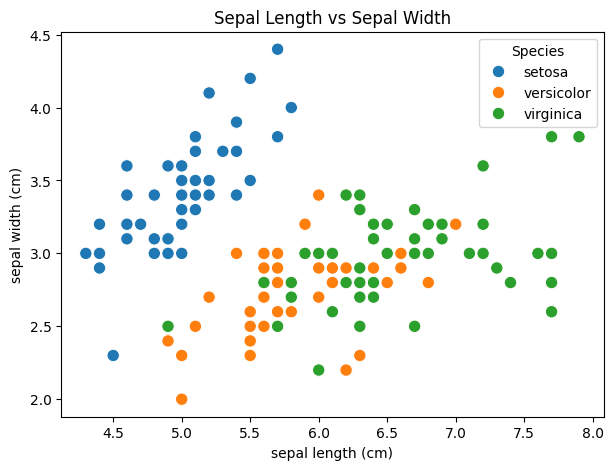

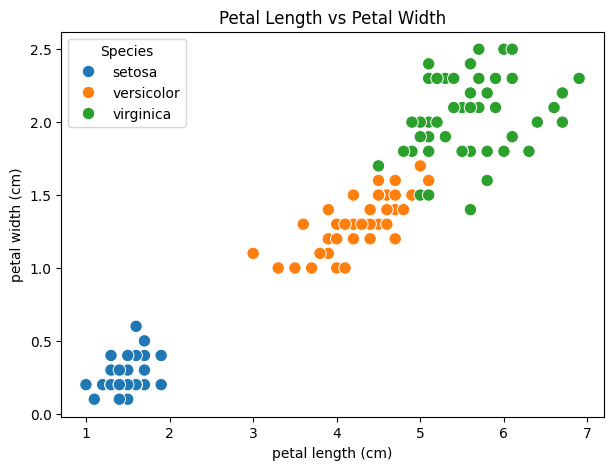

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Count of each flower species
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Species")
plt.title("Count of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Count")
plt.show()

# 2. Sepal length vs Sepal width
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="sepal length (cm)",
    y="sepal width (cm)",
    hue="Species",
    s=80
)
plt.title("Sepal Length vs Sepal Width")
plt.show()

# 3. Petal length vs Petal width
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="Species",
    s=80
)
plt.title("Petal Length vs Petal Width")
plt.show()

Training Samples: 120
Testing Samples: 30

Model Training Completed!

Model Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



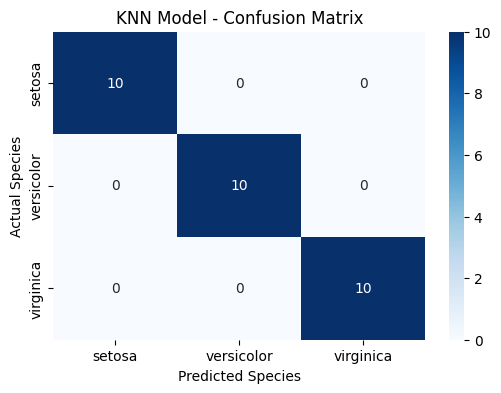

In [5]:

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Separate input and output
X = df.drop("Species", axis=1)
y = iris.target

# 2. Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# 3. Create KNN model
model = KNeighborsClassifier(n_neighbors=5)

# 4. Train model
model.fit(X_train, y_train)

print("\nModel Training Completed!")

# 5. Predict test data
y_pred = model.predict(X_test)

# 6. Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy: {:.2f}%".format(accuracy * 100))

# 7. Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# 8. Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("KNN Model - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()


In [7]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = model.predict(new_flower)
flower_name = iris.target_names[prediction[0]]

print("Predicted Flower Species:", flower_name)

probabilities = model.predict_proba(new_flower)[0]

for name, probability in zip(iris.target_names, probabilities):
    print(f"{name}: {probability * 100:.2f}%")

Predicted Flower Species: setosa
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%


In [8]:
import pickle

with open("iris_model.pkl", "wb") as file:
    pickle.dump(model, file)

with open("iris_names.pkl", "wb") as file:
    pickle.dump(iris.target_names, file)

print("Model saved successfully!")

Model saved successfully!
